# Google MLCC: standalone Colab edition

Run the setup cell in a fresh Colab runtime, then run every cell from top to bottom. Setup downloads the original course data and installs compatible dependencies, including `google-ml-edu` (imported as `ml_edu`) for taxi/rice. No course ZIP is required. TensorFlow 2.21 and Keras 3.12+ adapt those exercises to current Python 3.13 Colab; the original TF 2.18/NumPy 2.0 pins do not support Python 3.13.

`USE_GOOGLE_DRIVE=True` saves measured results, models, and task execution evidence to `MyDrive/HaiLong_Colab_Results/01_google_mlcc`. Save this notebook in Drive and save it after running to retain cell outputs. The completion report requires every computational stage and full original data/epochs. Website quizzes and interactive exercises have separate progress.

Original source: https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/numerical_data_bad_values.ipynb


In [1]:
# Standalone Google MLCC setup. Start a fresh Colab runtime, then Run all.
# No ZIP or eng-edu clone is required. Full original data/tasks only.
from pathlib import Path
import os, sys, subprocess, importlib.metadata as metadata
import hashlib, json, shutil, urllib.request, platform, uuid
from datetime import datetime, timezone
from packaging.requirements import Requirement

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  # retained for compatibility; full completion requires False
if QUICK_RUN:
    raise ValueError('Use QUICK_RUN=False to execute the full original exercise.')
NOTEBOOK_NAME = '04_numerical_data_bad_values.ipynb'
DEPENDENCY_PROFILE = 'basic'
REQUIREMENTS = ['numpy>=1.26,<3', 'pandas>=2.2,<3', 'matplotlib>=3.9,<4']
REQUIRED_TASKS = ['task_1_summary_statistics', 'task_2_visualize_samples', 'task_3_all_four_weeks', 'task_4_all_seven_days', 'task_5_all_four_thursdays']
DATA_SOURCES = []
ORIGINAL_SOURCE = 'https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/numerical_data_bad_values.ipynb'
VISUALIZATION_ADAPTATION = None

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# TensorFlow 2.21 has Python 3.13 wheels; original TF 2.18 pins do not.
# Set Keras mode before importing TensorFlow or Keras.
if DEPENDENCY_PROFILE in ('google', 'fairness'):
    if DEPENDENCY_PROFILE == 'fairness':
        if any(n in sys.modules for n in ('tensorflow', 'keras', 'tf_keras')):
            if os.environ.get('TF_USE_LEGACY_KERAS') != '1':
                raise RuntimeError('Select Runtime > Disconnect and delete runtime, reconnect, then Run all: MinDiff needs legacy Keras selected before TensorFlow import.')
        os.environ['TF_USE_LEGACY_KERAS'] = '1'
    else:
        if os.environ.get('TF_USE_LEGACY_KERAS') == '1' and any(n in sys.modules for n in ('tensorflow', 'keras', 'tf_keras')):
            raise RuntimeError('Start a fresh runtime after fairness before running this Keras 3 notebook.')
        os.environ.pop('TF_USE_LEGACY_KERAS', None)
    os.environ['KERAS_BACKEND'] = 'tensorflow'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['COURSE_SMOKE'] = '0'
os.environ['WANDB_MODE'] = 'offline'

# google-ml-edu is the distribution that provides the ml_edu import.
IMPORT_NAMES = {'google-ml-edu':'ml_edu', 'tf-keras':'tf_keras',
    'tensorflow-model-remediation':'tensorflow_model_remediation',
    'scikit-learn':'sklearn'}
def installed_version(package):
    try:
        return metadata.version(package)
    except metadata.PackageNotFoundError:
        return None
missing, loaded_changes = [], []
for text in REQUIREMENTS:
    req = Requirement(text)
    version = installed_version(req.name)
    if version is None or version not in req.specifier:
        missing.append(text)
        module = IMPORT_NAMES.get(req.name, req.name.replace('-', '_'))
        if module in sys.modules:
            loaded_changes.append(module)
if missing and IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--disable-pip-version-check', *missing])
    if loaded_changes:
        raise RuntimeError('Installed required versions. Select Runtime > Restart session, then Run all again; old loaded modules: ' + ', '.join(loaded_changes))
elif missing:
    raise RuntimeError('Prepared for Colab. Missing compatible local packages: ' + ', '.join(missing))

if IN_COLAB:
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
else:
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Run in Colab or inside HaiLong_Colab_Exercises.')
COURSE_DIR = COURSE_ROOT / '01_google_mlcc'
COURSE_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(COURSE_DIR)
DATA = COURSE_DIR / 'data'
DATA.mkdir(exist_ok=True)
DRIVE_DIR = None
if IN_COLAB and USE_GOOGLE_DRIVE:
    if not Path('/content/drive/MyDrive').is_dir():
        drive.mount('/content/drive', timeout_ms=300000)
    DRIVE_DIR = Path('/content/drive/MyDrive/HaiLong_Colab_Results/01_google_mlcc')
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
for folder in ('results', 'models'):
    target = COURSE_DIR / folder
    if DRIVE_DIR is not None:
        (DRIVE_DIR / folder).mkdir(exist_ok=True)
        if not target.exists():
            target.symlink_to(DRIVE_DIR / folder, target_is_directory=True)
    target.mkdir(exist_ok=True)
RESULTS, MODELS = COURSE_DIR / 'results', COURSE_DIR / 'models'
for spec in DATA_SOURCES:
    target = DATA / spec['filename']
    if not target.is_file():
        temporary = target.with_suffix(target.suffix + '.download')
        print('Downloading original Google course data:', spec['url'])
        urllib.request.urlretrieve(spec['url'], temporary)
        if hashlib.sha256(temporary.read_bytes()).hexdigest() != spec['sha256']:
            raise ValueError('Downloaded dataset differs from verified original: ' + spec['filename'])
        temporary.replace(target)
    if hashlib.sha256(target.read_bytes()).hexdigest() != spec['sha256']:
        raise ValueError('Existing data differs from the original course dataset: ' + str(target))

EXECUTED_TASKS = {}
COLAB_CONTEXT = {'notebook': NOTEBOOK_NAME, 'run_id': str(uuid.uuid4()),
    'started_at_utc': datetime.now(timezone.utc).isoformat(),
    'in_hosted_colab': IN_COLAB, 'quick_run': False,
    'python': platform.python_version(),
    'versions': {Requirement(r).name: installed_version(Requirement(r).name) for r in REQUIREMENTS},
    'original_source': ORIGINAL_SOURCE, 'data_sources': DATA_SOURCES,
    'visualization_adaptation': VISUALIZATION_ADAPTATION}
def mark_task(name, **evidence):
    if name not in REQUIRED_TASKS:
        raise KeyError(name)
    EXECUTED_TASKS[name] = {'recorded_at_utc': datetime.now(timezone.utc).isoformat(), **evidence}
    checkpoint = {**COLAB_CONTEXT, 'last_completed_stage': name,
        'updated_at_utc': datetime.now(timezone.utc).isoformat(),
        'missing_tasks': sorted(set(REQUIRED_TASKS) - set(EXECUTED_TASKS)),
        'task_evidence': EXECUTED_TASKS, 'course_website_completion_confirmed': False}
    (RESULTS / (Path(NOTEBOOK_NAME).stem + '_progress.json')).write_text(
        json.dumps(checkpoint, indent=2, allow_nan=False), encoding='utf-8')
    if DRIVE_DIR is not None:
        for folder in ('results', 'models'):
            source, target = COURSE_DIR / folder, DRIVE_DIR / folder
            if source.resolve() != target.resolve():
                shutil.copytree(source, target, dirs_exist_ok=True)
def finish_run(context):
    missing_tasks = sorted(set(REQUIRED_TASKS) - set(EXECUTED_TASKS))
    if missing_tasks:
        raise RuntimeError('Required exercise stages did not run: ' + ', '.join(missing_tasks))
    report = {**context, 'finished_at_utc': datetime.now(timezone.utc).isoformat(),
        'full_original_computational_tasks_executed': True,
        'course_website_completion_confirmed': False,
        'required_tasks': REQUIRED_TASKS, 'task_evidence': EXECUTED_TASKS,
        'note': 'Execution evidence covers this notebook. It does not certify website quizzes, interactive exercises, or personal reflection.'}
    path = RESULTS / (Path(NOTEBOOK_NAME).stem + '_completion.json')
    path.write_text(json.dumps(report, indent=2, allow_nan=False), encoding='utf-8')
    if DRIVE_DIR is not None:
        for folder in ('results', 'models'):
            source, target = COURSE_DIR / folder, DRIVE_DIR / folder
            if source.resolve() != target.resolve():
                shutil.copytree(source, target, dirs_exist_ok=True)
        print('Saved computational progress and artifacts to:', DRIVE_DIR)
    print('Full original computational stages executed:', NOTEBOOK_NAME)
    print('Completion evidence:', path)
    return report
print('Setup ready:', NOTEBOOK_NAME, '| full course data |', DEPENDENCY_PROFILE)

Setup ready: 04_numerical_data_bad_values.ipynb | full course data | basic


Source: https://github.com/google/eng-edu/blob/main/ml/cc/exercises/numerical_data_bad_values.ipynb

Completed Apache-2.0 Google exercise. All five tasks are covered; the day-slicing endpoint is corrected to include 50 rows.


In [2]:
#@title Copyright 2023 Google LLC. Double-click for license information.
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

# Colabs

Machine Learning Crash Course uses Colaboratory (Colab) notebooks for all programming exercises. Colab is Google's implementation of [Jupyter Notebook](https://jupyter.org/). For more information about Colabs and how to use them, go to [Welcome to Colaboratory](https://research.google.com/colaboratory).

# Numerical data - Find the bad part of the dataset

This Colab programming exercise is part of the Machine Learning Crash Course module [Working with numerical data](https://developers.google.com/machine-learning/crash-course/numerical-data). It is the final of two Colabs focused on data.

## What to expect

In the section, [First steps with numerical data](https://developers.google.com/machine-learning/crash-course/numerical-data/first-steps), you learned how to do the following:
- Visualize your data in plots or graphs.
- Evaluate potential features and labels mathematically.
- Find [**outliers**](https://developers.google.com/machine-learning/glossary/#outliers).

This exercise guides you through visual and mathematical ways to find hidden _bad_ values in a dataset. You'll use scatter plots and basic statistics to locate unreliable values in the dataset.

## The Dataset

The dataset for this exercise is fictitious. It contains 1,400 rows. Each row contains the following two columns:

* **calories**, which is the number of breakfast calories as determined by a nutritionist.
* **test_score**, which is the student's score on a math test. A reliable program determines the value of `test_score`.

The data pool consists of 50 students, each evaluated on 28 consecutive days. So, rows 0-49 show how each of the students performed on the first day, rows 50-99 show how each of the students performed on the second day, and so on.

The dataset aims to determine the relationship between the number of calories a student ate for breakfast and their test scores. However, your goal is simply to determine whether some values in the dataset are bad.

In [3]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '3')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '1')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
# Colab setup above selects this course folder.
DATA = Path('data')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)

In [4]:
# @title Setup - Import relevant modules

# The following code imports relevant modules that
# enable you to run the Colab.
# If you encounter technical issues running some of the code sections
# that follow, try running this section again.

import pandas as pd
from matplotlib import pyplot as plt
import io

# The following lines adjust the granularity of reporting.
pd.options.display.max_rows = 10
pd.options.display.float_format = "{:.1f}".format

In [5]:
# @title Setup - Define the dataset

# The following code defines the dataset that
# you'll use in the Colab.
# If you encounter technical issues running some of the code sections
# that follow, try running this section again.

dataset = '''calories,test_score
201,76
142,72
397,84
294,79
334,76
173,60
117,59
174,60
333,80
383,83
77,59
39,62
242,73
7,51
140,63
73,66
102,61
5,48
339,88
388,92
374,86
358,81
292,76
167,70
300,80
348,77
68,49
1,55
198,63
154,74
220,75
9,58
129,56
108,55
356,81
383,96
299,86
107,62
117,67
103,54
110,56
80,57
125,57
132,71
176,73
390,98
199,63
5,56
99,56
39,49
251,67
71,57
7,52
28,49
139,61
227,77
268,82
113,70
32,57
1,51
217,64
248,67
76,60
388,90
9,43
315,86
49,47
97,53
251,72
224,65
299,75
325,81
45,47
203,67
326,83
329,82
282,79
203,61
117,63
218,68
262,75
73,64
205,69
54,51
296,83
132,63
16,45
363,80
138,62
181,64
13,49
294,86
374,85
338,79
375,87
260,80
375,93
234,74
103,64
322,75
210,64
280,79
110,65
329,87
94,55
399,88
264,81
88,61
34,48
373,81
268,80
333,87
208,71
109,68
142,57
39,63
84,66
263,78
247,74
172,74
303,79
92,60
107,62
49,54
293,73
238,72
341,85
48,54
25,52
189,69
230,74
206,78
190,63
237,68
305,72
22,55
223,70
62,62
25,50
115,67
220,81
123,62
210,72
39,57
13,53
88,63
56,62
285,83
50,51
369,94
174,60
206,63
236,77
370,90
66,53
178,72
167,71
133,71
157,64
298,78
1,58
99,55
324,91
389,97
107,68
371,93
36,55
365,90
131,71
132,63
149,70
126,68
254,78
294,71
75,57
224,67
221,78
219,71
307,81
205,64
209,70
382,90
396,98
118,60
367,89
367,83
203,65
33,49
395,97
154,60
205,79
188,63
345,76
258,80
258,70
353,79
282,86
356,91
367,81
91,67
183,82
47,58
118,72
157,83
70,58
172,93
45,58
28,50
92,74
187,80
10,60
76,70
174,81
111,79
91,75
168,83
29,48
181,90
122,80
63,71
193,85
186,82
145,71
77,62
193,87
100,61
71,71
154,78
52,59
46,65
66,55
62,62
51,57
41,67
24,57
186,80
4,59
77,70
29,63
28,49
61,65
26,58
127,83
199,97
68,61
145,84
102,62
50,67
93,70
169,85
119,67
312,78
341,78
67,66
17,48
45,52
24,48
47,58
102,55
280,82
220,73
192,61
269,83
373,81
160,71
290,84
264,76
48,55
269,75
204,76
282,80
112,68
390,87
270,74
247,72
16,46
363,89
133,65
185,64
331,92
16,53
310,87
66,48
128,71
160,72
308,76
225,64
34,56
222,77
392,85
97,53
222,68
302,87
378,85
61,61
161,63
129,57
43,54
116,62
173,71
189,65
361,80
187,77
314,73
341,91
165,59
44,63
184,75
341,82
119,55
70,63
165,68
394,92
80,54
65,61
29,55
64,65
310,83
384,91
304,88
216,66
6,53
55,57
249,84
395,81
41,50
334,86
394,97
100,56
125,61
14,49
61,53
143,72
373,86
238,77
138,59
388,88
357,79
20,54
82,52
261,75
210,73
15,52
210,69
364,92
365,95
132,55
143,68
40,50
88,64
35,55
18,44
56,47
109,55
268,78
178,67
399,82
11,45
235,74
215,73
200,69
220,78
249,82
250,79
121,68
210,71
165,70
265,79
290,87
384,88
207,69
16,54
193,62
307,75
292,76
312,78
345,83
67,56
180,75
126,69
299,86
143,60
251,66
371,86
25,59
27,56
159,59
125,69
114,56
66,50
240,82
184,68
196,74
21,44
254,73
364,86
127,59
347,93
157,71
161,65
315,83
57,50
276,79
69,49
300,79
83,56
199,75
367,95
247,83
15,49
136,72
341,87
129,67
284,82
248,70
68,55
320,81
280,80
36,62
272,85
171,76
161,74
307,77
365,84
159,58
299,86
45,58
244,73
215,68
60,50
259,75
269,76
382,88
61,48
185,74
40,61
373,87
326,86
373,93
77,55
358,94
70,48
303,87
220,68
85,64
224,81
94,55
167,63
329,86
137,60
246,76
112,62
22,47
99,53
58,55
170,61
196,73
105,58
241,80
259,84
248,71
357,92
262,75
105,60
37,58
347,88
106,54
102,57
184,70
166,68
63,64
301,85
306,72
44,52
331,90
159,67
72,53
208,77
284,83
168,74
198,66
291,84
218,80
74,49
279,82
244,83
263,74
287,79
194,77
359,84
364,85
391,82
278,78
13,51
111,60
169,72
339,78
213,69
95,65
159,58
214,64
3,47
234,77
332,75
308,87
196,73
95,59
350,77
29,60
220,69
187,77
50,52
91,64
326,82
236,70
247,70
174,70
213,63
184,68
79,53
121,67
363,89
149,72
275,77
320,77
319,80
128,54
319,83
361,88
49,57
374,92
333,83
188,68
242,82
376,93
107,58
282,72
0,42
26,58
209,79
58,55
182,68
227,68
48,54
347,82
28,60
79,49
155,69
193,78
282,77
180,95
176,87
51,69
137,76
158,78
102,62
170,92
101,69
44,63
199,84
39,50
43,59
15,57
55,64
162,91
39,61
12,45
84,64
13,48
171,93
127,73
1,50
66,65
2,53
92,60
193,91
36,51
31,54
199,90
5,56
103,65
124,76
80,58
0,49
51,67
108,81
66,66
96,72
54,61
85,71
122,72
99,75
135,82
30,59
58,56
116,81
78,60
119,79
47,63
74,66
224,64
237,81
267,71
262,68
314,76
354,84
232,71
72,55
98,57
55,56
244,78
222,65
364,80
4,46
342,82
341,85
200,71
208,65
339,80
128,65
189,64
10,45
278,74
208,79
257,79
232,69
148,58
146,61
158,64
215,69
344,84
352,85
65,55
254,67
273,85
256,71
107,66
169,75
34,61
360,90
282,78
36,46
289,80
186,62
18,45
190,60
244,74
191,74
389,82
355,90
70,57
10,52
120,61
204,70
199,70
131,58
399,88
111,67
36,60
22,46
385,91
59,57
41,56
181,60
338,81
335,77
390,97
271,75
167,63
349,76
325,77
90,67
292,81
298,86
185,74
25,51
218,69
42,57
377,91
332,90
1,53
9,43
298,85
186,63
40,51
74,49
259,76
375,87
51,60
165,70
280,78
92,55
316,79
358,92
43,58
294,74
199,76
121,57
311,88
205,79
87,64
3,59
128,55
183,69
339,91
101,63
181,68
361,83
371,94
76,49
252,67
102,55
1,53
234,80
217,64
351,92
360,95
336,81
19,50
353,76
154,59
263,84
249,76
118,65
187,70
277,72
293,71
220,76
289,72
250,71
136,66
96,55
284,73
270,82
238,75
347,77
322,83
13,50
79,57
33,58
11,58
34,58
376,90
242,79
351,82
57,51
22,50
226,77
228,68
253,71
363,86
144,68
55,55
98,59
373,86
85,51
128,61
332,81
59,57
55,47
351,81
96,51
309,88
323,80
105,59
290,73
377,82
352,80
276,71
251,77
224,81
277,86
141,66
143,64
111,63
253,71
354,94
122,67
358,79
86,52
222,80
130,65
53,52
318,88
219,72
221,67
191,66
82,64
35,57
176,65
110,53
252,71
21,60
12,43
63,52
85,64
118,64
215,70
27,52
142,66
387,80
334,82
147,56
154,67
285,84
371,80
358,89
144,56
283,76
44,61
298,79
318,74
74,54
229,68
308,89
391,95
377,93
117,60
385,92
391,94
244,66
350,87
272,72
268,77
293,86
188,68
171,63
250,79
239,68
389,88
92,67
129,57
348,89
278,84
160,69
245,66
275,77
249,74
332,81
388,90
158,65
60,62
325,87
216,72
31,55
397,86
271,76
192,70
59,50
195,72
383,81
267,81
279,76
135,64
362,85
37,50
384,84
49,60
49,60
115,56
199,68
203,65
326,75
333,92
153,62
248,72
212,69
38,49
361,87
302,86
381,94
43,62
79,55
274,74
44,47
252,79
188,62
357,84
94,65
143,66
60,49
26,56
193,65
363,84
322,87
120,67
248,73
312,89
298,81
142,73
261,85
272,72
49,58
249,74
204,79
34,58
69,53
180,71
210,70
59,53
47,58
39,66
192,97
177,91
109,69
177,82
67,66
107,71
70,58
185,93
49,53
126,74
96,64
37,48
152,79
67,72
177,86
13,61
123,67
154,75
81,69
93,73
66,72
61,67
53,58
152,81
112,72
8,43
159,77
9,53
133,76
110,75
25,59
144,83
155,81
1,45
50,60
6,55
116,70
117,82
135,74
93,64
190,90
55,65
189,85
60,64
183,95
75,57
135,70
156,80
276,83
298,72
146,70
339,76
46,53
0,55
355,87
53,61
75,56
233,67
336,92
342,89
378,85
319,84
216,75
72,52
232,81
156,74
281,75
398,95
312,90
285,83
228,79
288,85
145,61
0,45
159,74
383,85
121,69
28,59
263,72
72,52
70,60
73,64
9,47
320,87
155,66
273,70
187,67
372,93
324,74
13,46
1,43
263,73
28,57
102,64
390,88
386,82
45,50
10,44
216,79
17,59
221,78
398,81
95,51
340,78
29,62
145,57
80,49
196,65
299,86
42,60
158,58
392,89
130,56
299,88
18,59
4,52
337,77
290,73
58,59
136,59
270,83
161,75
376,97
100,65
341,83
250,70
213,73
344,93
287,83
18,58
290,71
229,76
66,53
344,81
392,84
254,80
4,44
298,72
58,49
342,77
227,72
184,63
33,52
112,69
101,57
310,74
152,64
303,83
301,82
385,95
370,91
285,70
341,85
41,47
311,89
127,62
174,74
264,79
125,70
213,74
148,63
303,87
392,91
205,77
139,65
273,73
116,62
169,60
71,58
141,72
236,77
163,58
221,66
303,89
89,57
258,77
326,83
181,73
97,68
255,77
218,71
345,93
16,48
77,53
368,88
69,57
129,66
257,82
346,83
383,81
320,84
315,86
89,54
252,75
124,60
65,65
365,78
363,94
168,60
112,60
259,75
384,97
100,64
382,81
87,66
124,54
249,68
341,92
134,65
210,76
386,92
287,87
328,85
376,85
333,78
319,82
313,88
223,66
230,75
103,66
256,79
368,84
309,88
129,58
187,75
388,89
257,79
210,70
168,66
325,78
318,84
336,87
233,73
374,81
93,56
23,59
390,82
97,64
385,92
386,89
209,63
30,49
335,85
295,77
70,58
247,67
107,62
347,91
72,63
46,53
41,48
114,54
145,67
373,86
124,53
387,97
18,46
85,67
344,93
142,56
243,67
87,65
258,70
290,87
399,96
137,58
48,59
157,67
148,64
9,56
175,60
290,81
100,52
233,66
41,46
100,64
49,56
235,80
308,79
322,89
148,60
33,55
397,91
75,57
6,47
102,59
166,75
60,59
54,62
352,80
353,79
380,81
283,81
395,91
69,64
184,69
64,59
98,56
92,60
291,75
343,93
322,78
29,45
17,46
362,78
179,73
64,56
4,59
59,49
267,73
4,44
388,85
311,78
257,69
346,82
188,73
185,66
41,55
179,63
340,81
112,58
99,61
364,82
253,67
145,61
195,69
214,73
346,81
356,86
215,78
394,81
277,77
199,75
35,62
62,64
161,65
138,68
37,49
6,55
169,67
10,58
30,56
190,61
36,53
221,74
134,66
297,73
36,49
8,48
58,56
45,63
148,83
90,74
187,89
111,70
33,60
75,62
71,73
79,65
87,59
36,64
139,85
3,58
32,50
58,63
72,65
50,53
39,63
7,47
97,71
120,77
78,58
22,59
9,52
60,64
132,76
93,68
102,72
72,68
151,83
46,54
56,63
85,69
100,69
186,96
11,55
150,81
144,85
82,71
93,72
71,57
59,70
118,79
126,67
117,73
164,90
142,73
102,64
359,77
240,80
42,59
186,75
170,61
327,89
382,86
216,70
249,81
139,61
258,68
153,62
230,70
104,59
207,76
212,72
354,81
139,57
43,60
24,53
0,57
146,57
150,56
192,78
383,96
127,67
52,61
20,56
47,51
39,58
75,62
106,53
31,55
112,57
214,68
330,84
130,59
282,82
167,63
279,76
136,57
35,53
373,81
69,51
179,66
361,89
88,55
327,79
398,83
237,76
175,68
112,68
372,96
229,70
112,57
331,85
157,73
36,52
64,54
237,78
343,86
141,56
394,85
151,58
193,62
289,70
285,70
359,90
395,89
38,52
339,75
41,51
378,82
313,76
269,77
372,88
34,51
243,67
310,74
62,52
113,70
113,70
394,84
297,72
303,88
182,70
34,54
24,46
343,90
141,67
129,59
67,57
312,88
276,79
35,62
324,80
375,82
189,76
195,66
44,50
'''

## Load the dataset into a DataFrame

The following code cell loads the dataset into a DataFrame named `training_df`.

In [6]:
training_df = pd.read_csv(io.StringIO(dataset), on_bad_lines='warn')

assert len(training_df) == 1400 and not training_df.isna().any().any()

### Task 1: Examine basic statistics

The following line of code generates basic statistics on the dataset:

In [7]:
display(training_df.describe())
training_df.describe().to_csv(RESULTS / 'bad_values_summary.csv')
mark_task('task_1_summary_statistics', rows=len(training_df))

,calories,test_score
count,1400.0,1400.0
mean,185.4,69.9
std,116.9,12.8
min,0.0,42.0
25%,80.0,59.0
50%,177.0,70.0
75%,285.0,80.0
max,399.0,98.0


Do the basic statistics imply outliers?

In [8]:
# @title Task 1: Solution (run this code block to view) { display-mode: "form" }

print("""The basic statistics do not suggest a lot of outliers.
The standard deviations are substantially less than the
means. Furthermore, the quartile boundaries are approximately
evenly spaced.""")

The basic statistics do not suggest a lot of outliers.
The standard deviations are substantially less than the
means. Furthermore, the quartile boundaries are approximately
evenly spaced.


## Define plotting functions

The following code cell uses [matplotlib](https://developers.google.com/machine-learning/glossary/#matplotlib) to create the following functions:

*  `plot_the_dataset`, which creates a scatter plot of random points in the dataset. Setting the `number_of_points_to_plot` to 1,400 causes the function to create a scatter plot of all 1,400 points in the dataset.
*  `plot_a_contiguous_portion_of_dataset`, which creates a scatter plot of all the points in the dataset from start to end. For example, setting `start` to 0 and `end` to 100 will produce a scatter plot of the first 100 points in the dataset.

You may optionally double-click the headline to see the matplotlib code.

In [9]:
#@title Define the plotting functions { display-mode: "form" }

# The following code defines the plotting functions that can be used to
# visualize the data.

def plot_the_dataset(feature, label, number_of_points_to_plot):
  """Plot N random points of the dataset."""

  # Label the axes.
  plt.xlabel(feature)
  plt.ylabel(label)

  # Create a scatter plot from n random points of the dataset.
  random_examples = training_df.sample(n=number_of_points_to_plot, random_state=42)
  plt.scatter(random_examples[feature], random_examples[label])

  # Render the scatter plot.
  plt.show()

def plot_a_contiguous_portion_of_dataset(feature, label, start, end):
  """Plot the data points from start to end."""

  # Label the axes.
  plt.xlabel(feature)
  plt.ylabel(label)

  # Create a scatter plot.
  plt.scatter(training_df.iloc[start:end][feature], training_df.iloc[start:end][label])

  # Render the scatter plot.
  plt.show()


print("Defined the following functions:")
print("  * plot_the_dataset")
print("  * plot_a_contiguous_portion_of_dataset")

Defined the following functions:
  * plot_the_dataset
  * plot_a_contiguous_portion_of_dataset


## Task 2: Visualize the dataset

Outliers might still be lurking in the dataset. Visualizing the dataset with a scatter plot might identify outliers hidden in basic statistics.

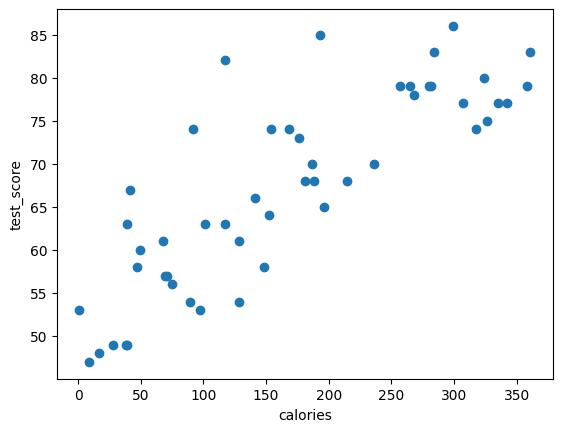

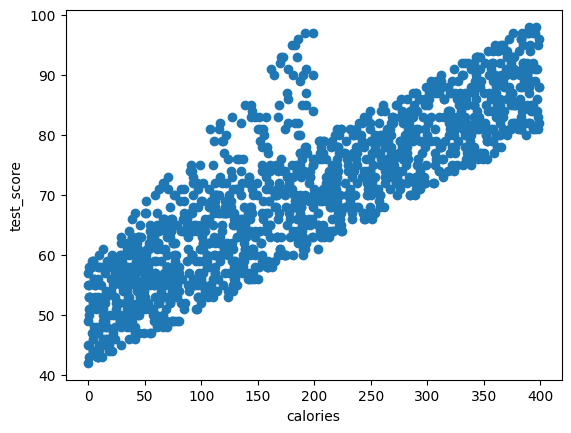

In [10]:
plot_the_dataset('calories','test_score',50)
plot_the_dataset('calories','test_score',len(training_df))

mark_task('task_2_visualize_samples', sampled_points=50, full_points=len(training_df))

Does the scatter plot of 50 random data points suggest outliers?
What happens if you increase the `number_of_points_to_plot`?

In [11]:
# @title Task 2: Solution (run this code block to view) { display-mode: "form" }

print("""Visualizing 50 data points doesn't imply any outliers.
However, as you increase the number of random data points to plot, a
clump of outliers appears. Notice the points with high test scores but less
than 200 calories.""")

Visualizing 50 data points doesn't imply any outliers.
However, as you increase the number of random data points to plot, a
clump of outliers appears. Notice the points with high test scores but less
than 200 calories.


## Task 3: Get statistics for each week

Possibly, different experimenters encoded `calories` differently.  For example, maybe the experiment involved a different encoder for week 0 than week 1? Run the following code cells to get statistics for each week. Can you see
significant differences for each week?



In [12]:
# Get statistics on Week 0
training_df[0:350].describe()

,calories,test_score
count,350.0,350.0
mean,181.3,69.7
std,117.5,12.8
min,1.0,43.0
25%,77.0,60.0
50%,172.0,70.0
75%,281.5,80.0
max,399.0,98.0


In [13]:
# Get statistics on Week 1
training_df[350:700].describe()

,calories,test_score
count,350.0,350.0
mean,184.4,69.8
std,112.4,12.8
min,0.0,42.0
25%,83.2,59.2
50%,185.0,70.0
75%,278.0,80.0
max,399.0,97.0


In [14]:
# Get statistics on Week 2
training_df[700:1050].describe()

,calories,test_score
count,350.0,350.0
mean,189.9,70.3
std,118.1,12.9
min,0.0,43.0
25%,82.8,60.0
50%,184.5,71.0
75%,289.8,81.0
max,398.0,97.0


In [15]:
# Get statistics on Week 3, then preserve all four week summaries.
display(training_df.iloc[1050:1400].describe())
weekly_stats = pd.concat({week:training_df.iloc[week*350:(week+1)*350].describe()
                         for week in range(4)}, names=['week','statistic'])
weekly_stats.to_csv(RESULTS / 'bad_values_all_week_statistics.csv')
mark_task('task_3_all_four_weeks', weeks=4, rows_each=350)

,calories,test_score
count,350.0,350.0
mean,186.2,69.8
std,120.0,12.7
min,0.0,44.0
25%,82.8,59.0
50%,166.5,69.0
75%,297.0,80.0
max,399.0,97.0


In [16]:
# @title Task 3: Solution (run this code block to view) { display-mode: "form" }

print("""The basic statistics for each week are pretty similar, so weekly
differences aren't a likely explanation for the outliers.""")

The basic statistics for each week are pretty similar, so weekly
differences aren't a likely explanation for the outliers.


## Task 4: Visualize by day of week

Weekly values didn't change, but perhaps different
experimenters were hired for different days of the week? Maybe the Monday
experimenter encoded values differently than the Tuesday experimenter?

The following code cell generates seven scatter plots--one for each day of the first week. Was each day of the week the same?



Day 0


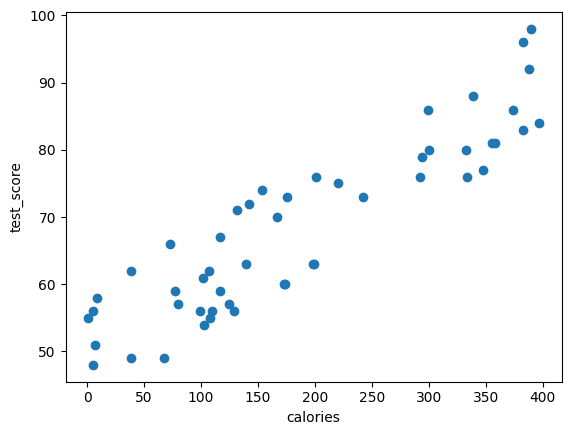


Day 1


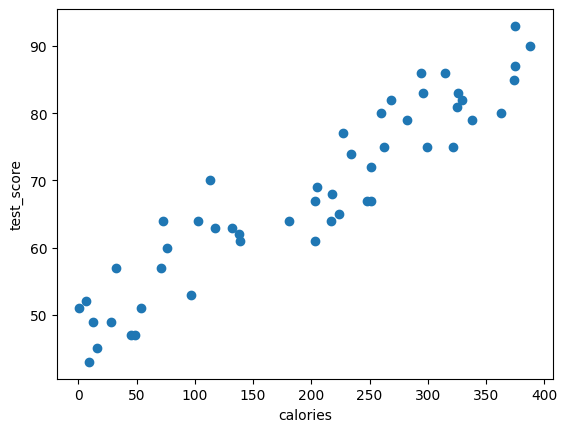


Day 2


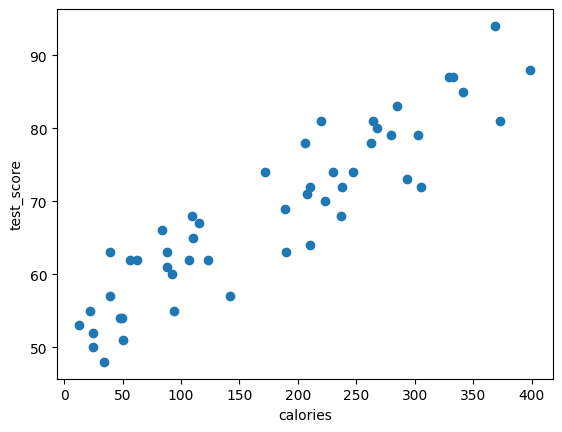


Day 3


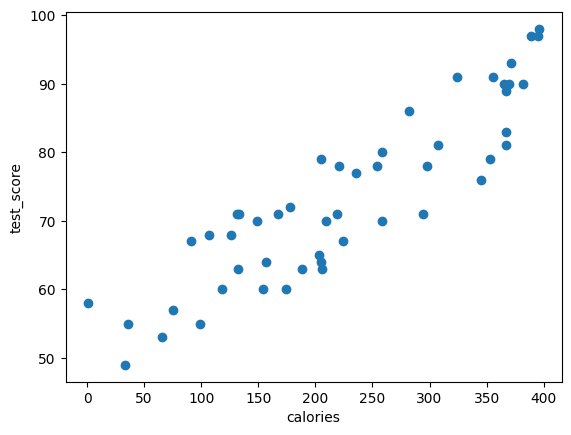


Day 4


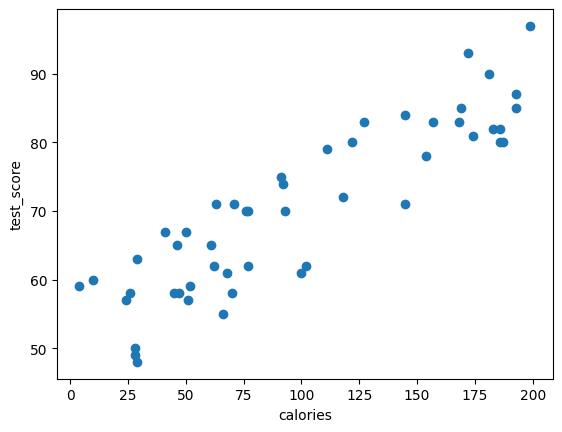


Day 5


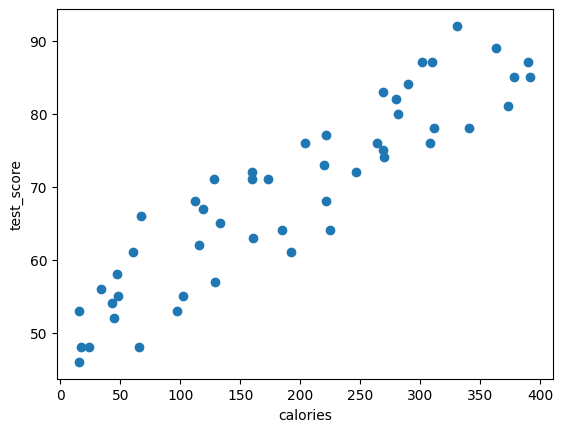


Day 6


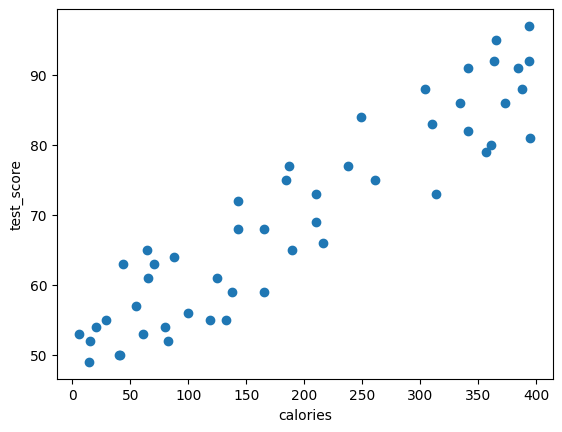

In [17]:
for i in range(0,7):
  start = i * 50
  end = start + 50
  print("\nDay %d" % i)
  plot_a_contiguous_portion_of_dataset("calories", "test_score", start, end)

mark_task('task_4_all_seven_days', days=7, rows_each=50)

In [18]:
# @title Task 4: Solution (run this code block to view) { display-mode: "form" }

print("""Wait a second--the calories value for Day 4 spans 0 to 200, while the
calories value for all the other Days spans 0 to 400. Something is wrong
with Day 4, at least on the first week.""")

Wait a second--the calories value for Day 4 spans 0 to 200, while the
calories value for all the other Days spans 0 to 400. Something is wrong
with Day 4, at least on the first week.


## Task 5: Use statistics to confirm your suspicions

You suspect Day 4 (Thursday) is encoded differently than other days of the week.
Write some code in the following code cell to confirm your suspicions.

In [19]:
import numpy as np
audit=training_df.assign(week=np.arange(len(training_df))//350,
                        day=(np.arange(len(training_df))//50)%7)
day_stats=audit.groupby('day')['calories'].agg(['count','mean','std','min','max'])
thursday=audit.loc[audit.day==4,'calories']
other=audit.loc[audit.day!=4,'calories']
print(day_stats.to_string())
print('Thursday / other-day mean:',thursday.mean()/other.mean())
print(audit.groupby(['week','day']).calories.mean().unstack().to_string())
day_stats.to_csv(RESULTS/'bad_values_day_audit.csv')
assert len(thursday)==200 and len(other)==1200
print('The scale discrepancy recurs on day index 4. Verify the encoding with the source before correcting values.')

audit.groupby(['week','day']).calories.agg(['count','mean','min','max']).to_csv(RESULTS / 'bad_values_week_day_statistics.csv')
mark_task('task_5_all_four_thursdays', thursday_rows=len(thursday), other_rows=len(other), thursday_mean=float(thursday.mean()), other_day_mean=float(other.mean()), mean_ratio=float(thursday.mean()/other.mean()))

     count  mean   std  min  max
day                             
0      200 200.3 115.1    1  399
1      200 208.3 115.8    1  390
2      200 199.5 114.9    6  399
3      200 201.0 116.4    0  396
4      200  93.0  55.6    0  199
5      200 196.2 117.4    0  398
6      200 199.8 125.5    1  399
Thursday / other-day mean: 0.4629880097913123
day      0     1     2     3     4     5     6
week                                          
0    188.1 195.3 176.0 226.8  99.0 190.3 193.3
1    191.1 208.0 197.9 198.2  87.0 214.8 193.6
2    199.5 183.7 249.2 199.2 101.7 197.1 199.2
3    222.5 246.4 174.8 180.0  84.3 182.4 213.3
The scale discrepancy recurs on day index 4. Verify the encoding with the source before correcting values.


In [20]:
# @title Task 5: Solution (expand this code block to view) { display-mode: "form" }

# You could use a variety of metrics to fully compare Thursday to the other
# six days, but this answer simply focuses on the mean.

running_total_of_thursday_calories = 0
running_total_of_non_thursday_calories = 0
count = 0
for week in range(0,4):
  for day in range(0,7):
    for subject in range(0,50):
      position = (week * 350) + (day * 50) + subject
      if (day == 4):  # Thursday
        running_total_of_thursday_calories += training_df['calories'][position]
      else:  # Any day except Thursday
        count += 1
        running_total_of_non_thursday_calories += training_df['calories'][position]

mean_of_thursday_calories = running_total_of_thursday_calories / 200
mean_of_non_thursday_calories = running_total_of_non_thursday_calories / 1200

print("The mean of Thursday calories is %.0f" % (mean_of_thursday_calories))
print("The mean of calories on days other than Thursday is %.0f" % (mean_of_non_thursday_calories))

The mean of Thursday calories is 93
The mean of calories on days other than Thursday is 201


## Save computational progress
Run the final cell after every exercise cell. It checks the required computational stages ran in this session, saves timestamped evidence, and synchronizes results/models to Drive. Save the notebook itself to retain its cell outputs. Website quiz/exercise progress is tracked separately by Google.


In [21]:
finish_run(COLAB_CONTEXT)

Saved computational progress and artifacts to: /content/drive/MyDrive/HaiLong_Colab_Results/01_google_mlcc
Full original computational stages executed: 04_numerical_data_bad_values.ipynb
Completion evidence: results/04_numerical_data_bad_values_completion.json


{'notebook': '04_numerical_data_bad_values.ipynb',
 'run_id': '23f91810-89dd-40e0-922f-c2a2839a1ee7',
 'started_at_utc': '2026-10-03T06:05:08.387177+00:00',
 'in_hosted_colab': True,
 'quick_run': False,
 'python': '3.12.13',
 'versions': {'numpy': '2.0.2', 'pandas': '2.2.2', 'matplotlib': '3.10.0'},
 'original_source': 'https://raw.githubusercontent.com/google/eng-edu/main/ml/cc/exercises/numerical_data_bad_values.ipynb',
 'data_sources': [],
 'visualization_adaptation': None,
 'finished_at_utc': '2026-10-03T06:05:11.589305+00:00',
 'full_original_computational_tasks_executed': True,
 'course_website_completion_confirmed': False,
 'required_tasks': ['task_1_summary_statistics',
  'task_2_visualize_samples',
  'task_3_all_four_weeks',
  'task_4_all_seven_days',
  'task_5_all_four_thursdays'],
 'task_evidence': {'task_1_summary_statistics': {'recorded_at_utc': '2026-10-03T06:05:09.442439+00:00',
   'rows': 1400},
  'task_2_visualize_samples': {'recorded_at_utc': '2026-10-03T06:05:10.020

In [22]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
}
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": null, "legacy_keras": null}
